In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive (1) (1).zip to archive (1) (1).zip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import zipfile
from pathlib import Path

# Find the uploaded ZIP file
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError("ZIP file not found. Upload your dataset first.")

zip_path = os.path.join("/content", zip_files[0])

# Extract dataset
extract_path = "/content/custom_segmentation_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

print("\nExtracted contents:")
for item in os.listdir(extract_path):
    print(item)

Dataset extracted successfully!
Location: /content/custom_segmentation_dataset

Extracted contents:
Image
metadata.csv
Mask


In [ ]:
import os

image_dir = None
mask_dir = None
metadata_path = None

for root, dirs, files in os.walk(extract_path):

    for folder in dirs:
        if folder.lower() == "image":
            image_dir = os.path.join(root, folder)

        elif folder.lower() == "mask":
            mask_dir = os.path.join(root, folder)

    for file in files:
        if file.lower() == "metadata.csv":
            metadata_path = os.path.join(root, file)

if image_dir is None or mask_dir is None:
    raise FileNotFoundError(
        "Could not find Image or Mask folders."
    )

print("Image folder:", image_dir)
print("Mask folder:", mask_dir)
print("Metadata file:", metadata_path)

print("\nNumber of image files:",
      len(os.listdir(image_dir)))

print("Number of mask files:",
      len(os.listdir(mask_dir)))

Image folder: /content/custom_segmentation_dataset/Image
Mask folder: /content/custom_segmentation_dataset/Mask
Metadata file: /content/custom_segmentation_dataset/metadata.csv

Number of image files: 290
Number of mask files: 290


In [ ]:
import glob
import os

image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp"]
mask_extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp"]

image_files = []

for ext in image_extensions:
    image_files.extend(
        glob.glob(os.path.join(image_dir, ext))
    )

mask_files = []

for ext in mask_extensions:
    mask_files.extend(
        glob.glob(os.path.join(mask_dir, ext))
    )

# Create filename mapping
mask_dict = {
    os.path.splitext(os.path.basename(f))[0].lower(): f
    for f in mask_files
}

paired_images = []
paired_masks = []

for img in sorted(image_files):

    name = os.path.splitext(os.path.basename(img))[0].lower()

    if name in mask_dict:
        paired_images.append(img)
        paired_masks.append(mask_dict[name])

print("Total images:", len(image_files))
print("Total masks:", len(mask_files))
print("Successfully matched pairs:", len(paired_images))
print("Images without matching masks:",
      len(image_files) - len(paired_images))

if len(paired_images) == 0:
    raise ValueError("No matching image-mask pairs found!")

assert len(paired_images) == len(paired_masks)

Total images: 290
Total masks: 290
Successfully matched pairs: 290
Images without matching masks: 0


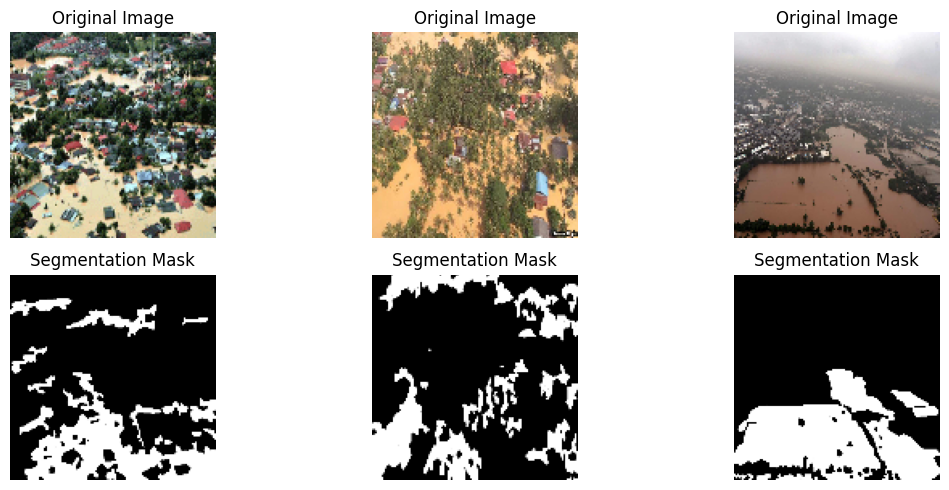

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img
import numpy as np

plt.figure(figsize=(12, 5))

for i in range(min(3, len(paired_images))):

    img = load_img(
        paired_images[i],
        target_size=(128, 128),
        color_mode="rgb"
    )

    mask = load_img(
        paired_masks[i],
        target_size=(128, 128),
        color_mode="grayscale"
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, i + 4)
    plt.imshow(mask, cmap="gray")
    plt.title("Segmentation Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import numpy as np

mask_sample = np.array(
    Image.open(paired_masks[0]).convert("L")
)

print("Mask shape:", mask_sample.shape)
print("Unique mask pixel values:",
      np.unique(mask_sample)[:30])

Mask shape: (551, 893)
Unique mask pixel values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]


In [ ]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
import numpy as np

IMG_SIZE = (128, 128)
BATCH_SIZE = 4

# Split dataset: 70% training, 30% remaining
train_images, temp_images, train_masks, temp_masks = train_test_split(
    paired_images,
    paired_masks,
    test_size=0.30,
    random_state=42
)

# Split remaining data into validation and testing
val_images, test_images, val_masks, test_masks = train_test_split(
    temp_images,
    temp_masks,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Testing images:", len(test_images))

Training images: 203
Validation images: 43
Testing images: 44


In [ ]:
def preprocess_image_mask(image_path, mask_path):

    # Load original image
    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    # Load segmentation mask
    mask = tf.io.read_file(mask_path)

    mask = tf.io.decode_image(
        mask,
        channels=1,
        expand_animations=False
    )

    mask.set_shape([None, None, 1])

    mask = tf.image.resize(
        mask,
        IMG_SIZE,
        method="nearest"
    )

    # Convert 0-255 binary masks to 0-1
    mask = tf.cast(mask, tf.float32)

    mask = tf.cond(
        tf.reduce_max(mask) > 1.0,
        lambda: mask / 255.0,
        lambda: mask
    )

    # Binary segmentation
    mask = tf.cast(mask > 0.5, tf.float32)

    return image, mask


In [ ]:
def create_dataset(images, masks, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (images, masks)
    )

    dataset = dataset.map(
        preprocess_image_mask,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(images),
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(
    train_images, train_masks, training=True
)

val_ds = create_dataset(
    val_images, val_masks
)

test_ds = create_dataset(
    test_images, test_masks
)

print("Training dataset ready!")
print("Validation dataset ready!")
print("Testing dataset ready!")

Training dataset ready!
Validation dataset ready!
Testing dataset ready!


In [ ]:
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Conv2DTranspose,
    concatenate
)

from tensorflow.keras.models import Model


def build_unet(input_shape=(128, 128, 3)):

    inputs = Input(input_shape)

    # Encoder 1
    c1 = Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(32, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    # Encoder 2
    c2 = Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(64, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    # Encoder 3
    c3 = Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(128, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    # Encoder 4
    c4 = Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(256, 3, activation='relu', padding='same')(c4)
    p4 = MaxPooling2D(2)(c4)

    # Bottleneck
    c5 = Conv2D(512, 3, activation='relu', padding='same')(p4)
    c5 = Conv2D(512, 3, activation='relu', padding='same')(c5)

    # Decoder 1
    u6 = Conv2DTranspose(256, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(256, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(256, 3, activation='relu', padding='same')(c6)

    # Decoder 2
    u7 = Conv2DTranspose(128, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(128, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(128, 3, activation='relu', padding='same')(c7)

    # Decoder 3
    u8 = Conv2DTranspose(64, 2, strides=2, padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(64, 3, activation='relu', padding='same')(u8)
    c8 = Conv2D(64, 3, activation='relu', padding='same')(c8)

    # Decoder 4
    u9 = Conv2DTranspose(32, 2, strides=2, padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(32, 3, activation='relu', padding='same')(u9)
    c9 = Conv2D(32, 3, activation='relu', padding='same')(c9)

    # Output
    outputs = Conv2D(
        1,
        1,
        activation='sigmoid'
    )(c9)

    return Model(inputs, outputs)


model = build_unet()

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 256) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8, 512) │  1,180,160 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 512) │  2,359,808 │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    524,544 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 512)              │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,760,097 (29.60 MB)

 Trainable params: 7,760,097 (29.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def dice_coef(y_true, y_pred, smooth=1e-6):

    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true_f) +
        tf.reduce_sum(y_pred_f) + smooth
    )


def jaccard_index(y_true, y_pred, smooth=1e-6):

    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    union = (
        tf.reduce_sum(y_true_f) +
        tf.reduce_sum(y_pred_f) -
        intersection
    )

    return (intersection + smooth) / (union + smooth)

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        dice_coef,
        jaccard_index
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "/content/best_unet_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

print("Training completed!")

Epoch 1/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - dice_coef: 3.7515e-11 - jaccard_index: 3.7515e-11 - loss: 0.6907
Epoch 1: val_loss improved from None to 0.64786, saving model to /content/best_unet_model.keras

Epoch 1: finished saving model to /content/best_unet_model.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 69s 610ms/step - dice_coef: 3.9248e-11 - jaccard_index: 3.9248e-11 - loss: 0.6835 - val_dice_coef: 4.0294e-11 - val_jaccard_index: 4.0294e-11 - val_loss: 0.6479 - learning_rate: 1.0000e-04
Epoch 2/15
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - dice_coef: 0.2270 - jaccard_index: 0.1633 - loss: 0.6107
Epoch 2: val_loss improved from 0.64786 to 0.52128, saving model to /content/best_unet_model.keras

Epoch 2: finished saving model to /content/best_unet_model.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 30s 71ms/step - dice_coef: 0.4575 - jaccard_index: 0.3408 - loss: 0.5776 - val_dice_coef: 0.6809 - val_jaccard_index: 0.5267 - val_loss: 0.5213 - learning_rate: 1.0000e-04
Epoch 3/15
51/51 ━━━━━━━━━━━━

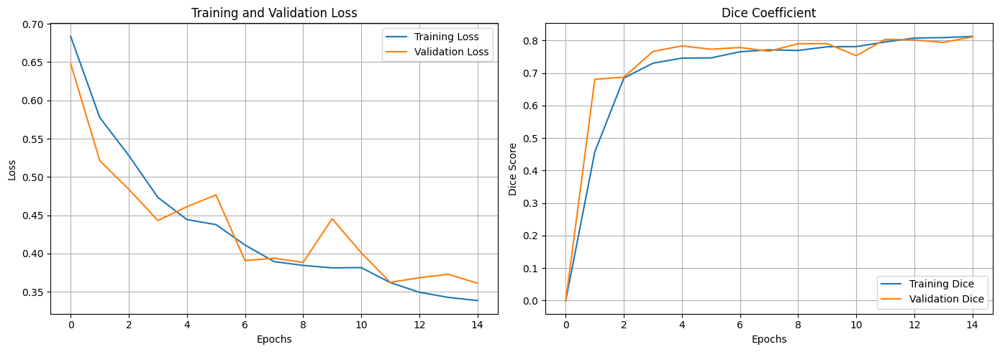

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

# Dice graph
plt.subplot(1, 2, 2)

plt.plot(history.history["dice_coef"], label="Training Dice")
plt.plot(history.history["val_dice_coef"], label="Validation Dice")

plt.title("Dice Coefficient")
plt.xlabel("Epochs")
plt.ylabel("Dice Score")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")

print("Test Loss:", test_results[0])
print("Test Dice:", test_results[1])
print("Test Jaccard:", test_results[2])

print("========================================")

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - dice_coef: 0.8189 - jaccard_index: 0.7041 - loss: 0.3254

========== FINAL TEST RESULTS ==========
Test Loss: 0.32540011405944824
Test Dice: 0.8189454674720764
Test Jaccard: 0.7040755748748779


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


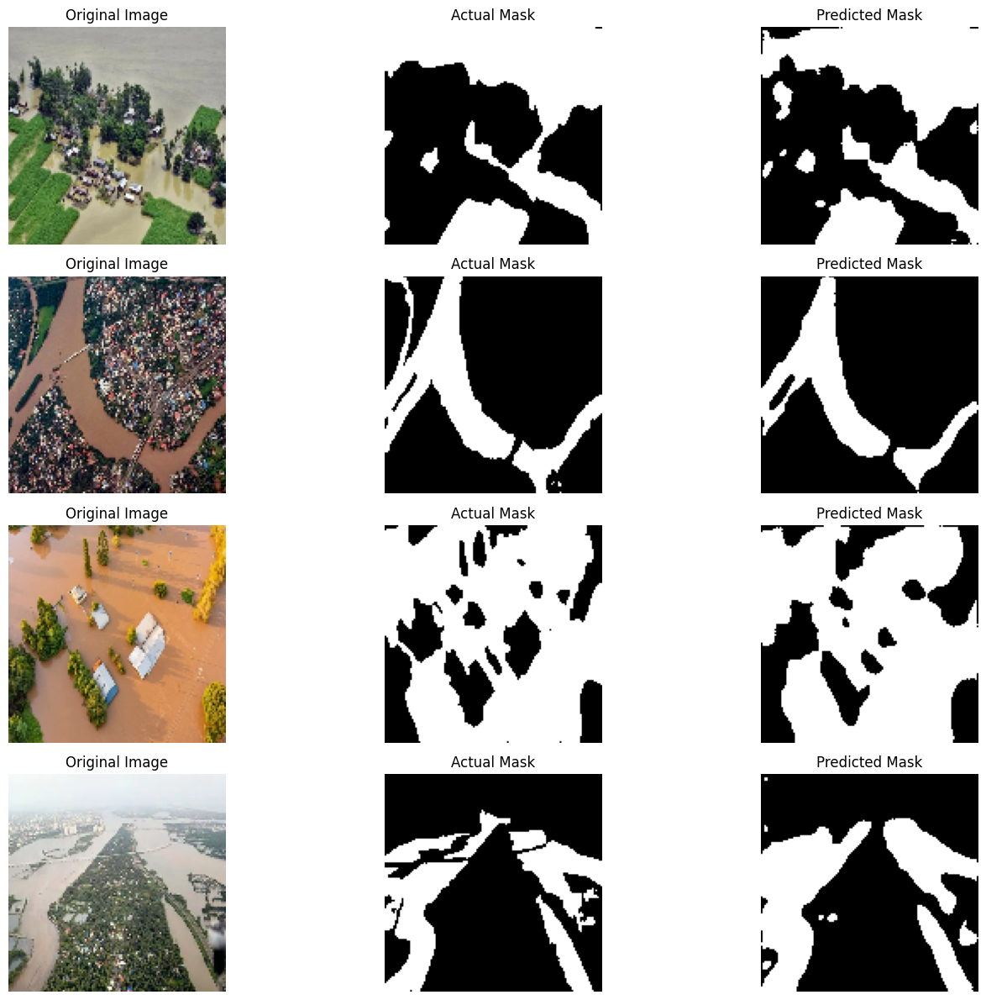

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get a batch of testing images
test_imgs, test_masks_batch = next(iter(test_ds))

# Generate predictions
predictions = model.predict(test_imgs)

# Convert predictions into binary masks
predicted_masks = (predictions > 0.5).astype(np.float32)

# Display results
num_images = min(4, len(test_imgs))

plt.figure(figsize=(15, 12))

for i in range(num_images):

    # Original image
    plt.subplot(num_images, 3, i * 3 + 1)

    plt.imshow(test_imgs[i].numpy())

    plt.title("Original Image")
    plt.axis("off")

    # Actual mask
    plt.subplot(num_images, 3, i * 3 + 2)

    plt.imshow(
        test_masks_batch[i].numpy().squeeze(),
        cmap="gray"
    )

    plt.title("Actual Mask")
    plt.axis("off")

    # Predicted mask
    plt.subplot(num_images, 3, i * 3 + 3)

    plt.imshow(
        predicted_masks[i].squeeze(),
        cmap="gray"
    )

    plt.title("Predicted Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model.save("/content/final_unet_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, UpSampling2D,
    Concatenate, Dropout, BatchNormalization,
    Activation, Add, Multiply
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Use the directories created during ZIP extraction
# image_dir = "/content/custom_segmentation_dataset/Image"
# mask_dir  = "/content/custom_segmentation_dataset/Mask"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def get_file_map(directory):
    file_map = {}

    for filename in os.listdir(directory):
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            key = os.path.splitext(filename)[0].lower()
            file_map[key] = os.path.join(directory, filename)

    return file_map


image_map = get_file_map(image_dir)
mask_map = get_file_map(mask_dir)

common_names = sorted(set(image_map) & set(mask_map))

image_paths = [image_map[name] for name in common_names]
mask_paths = [mask_map[name] for name in common_names]

print("Matched image-mask pairs:", len(image_paths))
print("Images without masks:", len(set(image_map) - set(mask_map)))
print("Masks without images:", len(set(mask_map) - set(image_map)))

if not image_paths:
    raise ValueError("No matching image-mask pairs found.")

Matched image-mask pairs: 290
Images without masks: 0
Masks without images: 0


In [ ]:
IMG_SIZE = 256

def load_image_mask(image_path, mask_path):

    # Load RGB image
    image = Image.open(image_path).convert("RGB")
    image = image.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.BILINEAR
    )

    image = np.asarray(image, dtype=np.float32) / 255.0

    # Load grayscale segmentation mask
    mask = Image.open(mask_path).convert("L")
    mask = mask.resize(
        (IMG_SIZE, IMG_SIZE),
        Image.Resampling.NEAREST
    )

    mask = np.asarray(mask, dtype=np.float32)

    # Binary segmentation: flooded = 1, non-flooded = 0
    mask = (mask > 0).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return image, mask


imgs = []
msks = []

for image_path, mask_path in zip(image_paths, mask_paths):

    image, mask = load_image_mask(image_path, mask_path)

    imgs.append(image)
    msks.append(mask)

imgs = np.array(imgs, dtype=np.float32)
msks = np.array(msks, dtype=np.float32)

print("Images shape:", imgs.shape)
print("Masks shape:", msks.shape)
print("Mask values:", np.unique(msks))

Images shape: (290, 256, 256, 3)
Masks shape: (290, 256, 256, 1)
Mask values: [0. 1.]


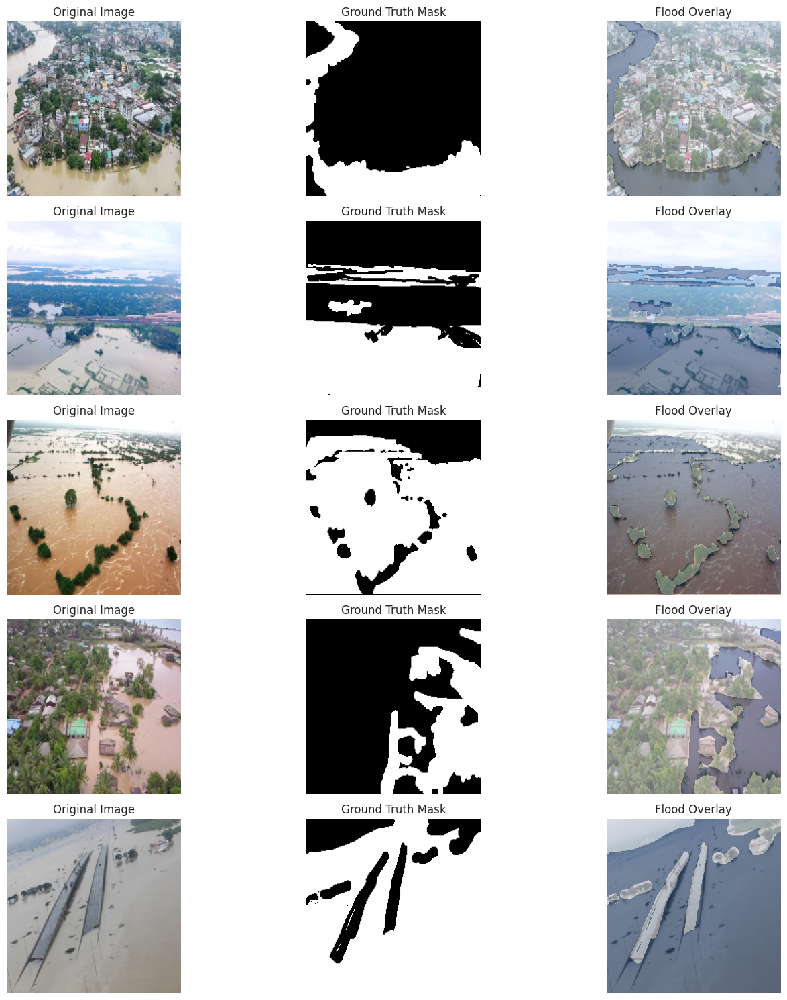

In [ ]:
def show_samples(images, masks, count=5):

    count = min(count, len(images))

    plt.figure(figsize=(15, count * 3))

    for i in range(count):

        idx = np.random.randint(len(images))

        plt.subplot(count, 3, i * 3 + 1)
        plt.imshow(images[idx])
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(count, 3, i * 3 + 2)
        plt.imshow(masks[idx].squeeze(), cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(count, 3, i * 3 + 3)
        plt.imshow(images[idx])
        plt.imshow(
            masks[idx].squeeze(),
            cmap="Blues",
            alpha=0.4
        )
        plt.title("Flood Overlay")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_samples(imgs, msks)

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    imgs, msks,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (203, 256, 256, 3)
Validation: (43, 256, 256, 3)
Testing: (44, 256, 256, 3)


In [ ]:
def conv_block(x, filters, dropout_rate=0.0):

    x = Conv2D(
        filters, 3, padding="same",
        kernel_initializer="he_normal"
    )(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    if dropout_rate > 0:
        x = Dropout(dropout_rate)(x)

    x = Conv2D(
        filters, 3, padding="same",
        kernel_initializer="he_normal"
    )(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    return x


def attention_gate(gating, skip, filters):

    gating_proj = Conv2D(
        filters, 1, padding="same"
    )(gating)

    skip_proj = Conv2D(
        filters, 1, padding="same"
    )(skip)

    combined = Add()([gating_proj, skip_proj])
    combined = Activation("relu")(combined)

    attention = Conv2D(
        1, 1, padding="same",
        activation="sigmoid"
    )(combined)

    return Multiply()([skip, attention])


def decoder_block(x, skip, filters, dropout_rate=0.0):

    x = UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(x)

    attended_skip = attention_gate(
        x, skip, filters
    )

    x = Concatenate()([x, attended_skip])

    x = conv_block(
        x, filters, dropout_rate
    )

    return x


def build_attention_unet(input_shape=(256, 256, 3)):

    inputs = Input(input_shape)

    # Encoder
    c1 = conv_block(inputs, 32, 0.1)
    p1 = MaxPooling2D()(c1)

    c2 = conv_block(p1, 64, 0.1)
    p2 = MaxPooling2D()(c2)

    c3 = conv_block(p2, 128, 0.2)
    p3 = MaxPooling2D()(c3)

    c4 = conv_block(p3, 256, 0.2)
    p4 = MaxPooling2D()(c4)

    # Bottleneck
    bn = conv_block(p4, 512, 0.3)

    # Decoder with attention gates
    d1 = decoder_block(bn, c4, 256, 0.2)
    d2 = decoder_block(d1, c3, 128, 0.2)
    d3 = decoder_block(d2, c2, 64, 0.1)
    d4 = decoder_block(d3, c1, 32, 0.1)

    # Binary segmentation output
    outputs = Conv2D(
        1, 1,
        activation="sigmoid",
        padding="same"
    )(d4)

    return Model(inputs, outputs)


model = build_attention_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      9,248 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 128,  │          0 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │     36,928 │ dropout_1[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ activation_3[0][

 Total params: 8,120,997 (30.98 MB)

 Trainable params: 8,115,109 (30.96 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
BATCH_SIZE = 8
EPOCHS = 15


callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        "/content/best_flood_attention_unet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8269 - loss: 0.4140   
Epoch 1: val_loss improved from None to 1.41089, saving model to /content/best_flood_attention_unet.keras

Epoch 1: finished saving model to /content/best_flood_attention_unet.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.8251 - loss: 0.4132 - val_accuracy: 0.4196 - val_loss: 1.4109 - learning_rate: 1.0000e-04
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.8165 - loss: 0.4300
Epoch 2: val_loss did not improve from 1.41089
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 352ms/step - accuracy: 0.8350 - loss: 0.3889 - val_accuracy: 0.4184 - val_loss: 3.6957 - learning_rate: 1.0000e-04
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - accuracy: 0.8451 - loss: 0.3759
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.

Epoch 3: val_loss did not improve from 1.41089
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 369ms/step - accuracy: 0.8387 - loss: 0.3829 - val_accuracy: 0.4184 - 

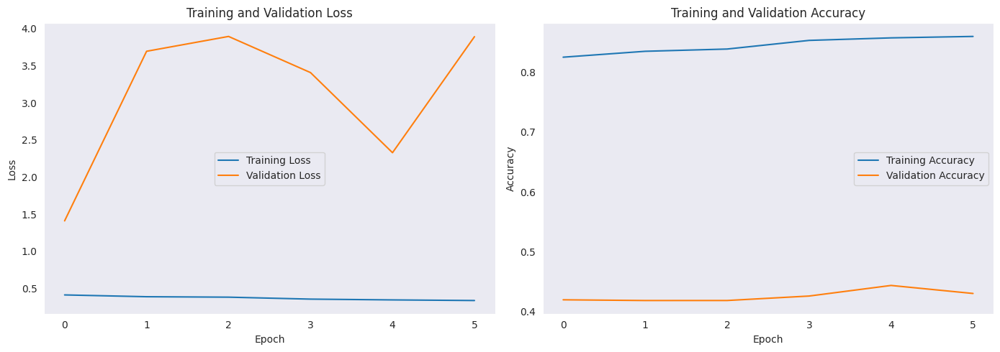

In [ ]:
def plot_training(history):

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()


plot_training(history)

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.4010 - loss: 1.4090
Test Loss: 1.4089561700820923
Test Accuracy: 0.4010162353515625


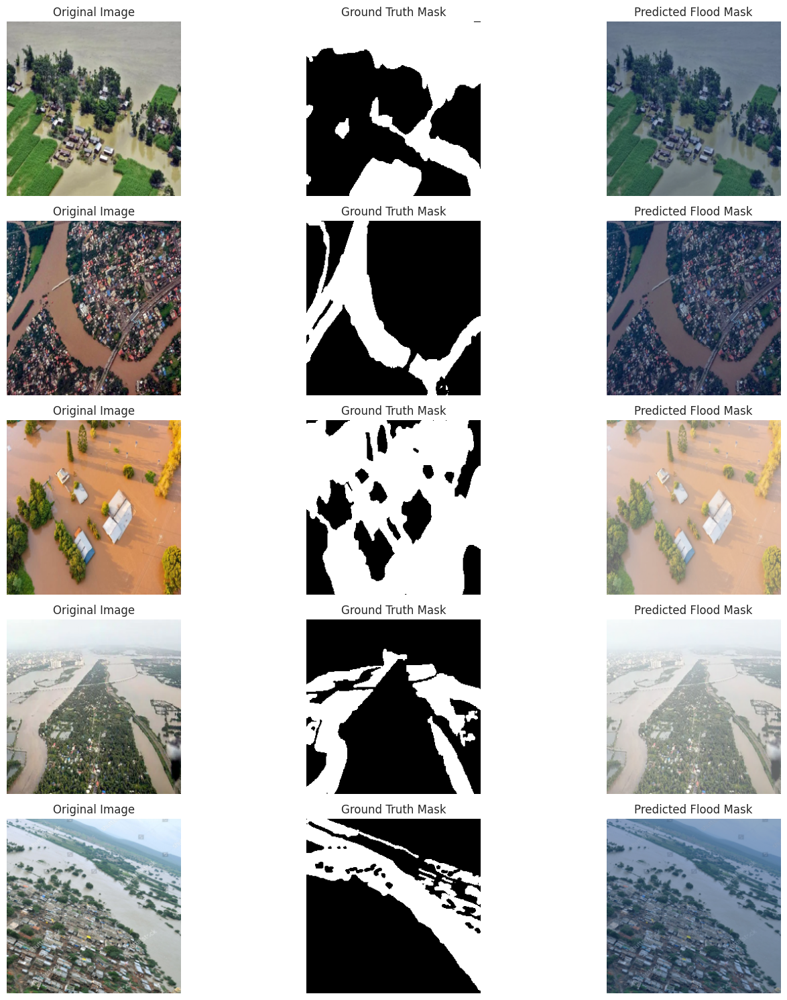

In [ ]:
def show_predictions(images, masks, model, count=5):

    count = min(count, len(images))

    predictions = model.predict(
        images[:count],
        verbose=0
    )

    plt.figure(figsize=(15, count * 3))

    for i in range(count):

        pred_mask = (
            predictions[i].squeeze() > 0.5
        ).astype(np.float32)

        plt.subplot(count, 3, i * 3 + 1)
        plt.imshow(images[i])
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(count, 3, i * 3 + 2)
        plt.imshow(masks[i].squeeze(), cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(count, 3, i * 3 + 3)
        plt.imshow(images[i])
        plt.imshow(
            pred_mask,
            cmap="Blues",
            alpha=0.4
        )
        plt.title("Predicted Flood Mask")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(X_test, y_test, model)

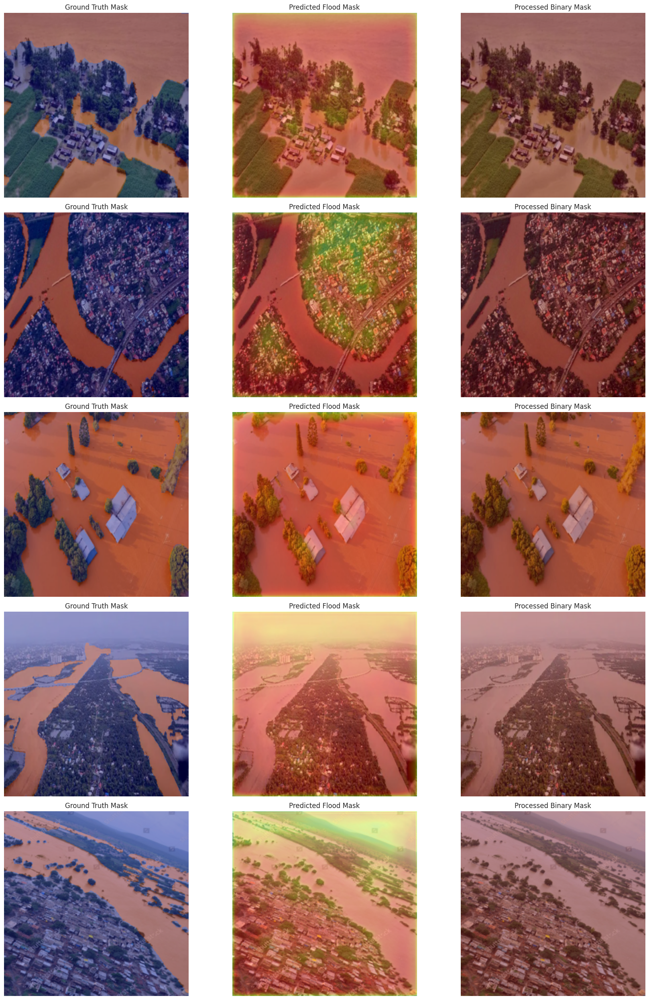

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

num_samples = min(5, len(X_test))

plt.figure(figsize=(18, 5 * num_samples))

for i in range(num_samples):

    # Select test image and ground-truth mask
    image = X_test[i]
    mask = y_test[i]  # Corrected variable name

    # Predict flood mask
    pred_mask = model.predict(
        image[np.newaxis, ...],
        verbose=0
    )[0]

    # Convert probabilities to binary mask
    processed_mask = (pred_mask > 0.5).astype(np.float32)

    # Column 1: Original image with ground-truth overlay
    plt.subplot(num_samples, 3, i * 3 + 1)
    plt.title("Ground Truth Mask")
    plt.imshow(image)
    plt.imshow(
        np.squeeze(mask),
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    plt.axis("off")

    # Column 2: Original image with predicted probabilities
    plt.subplot(num_samples, 3, i * 3 + 2)
    plt.title("Predicted Flood Mask")
    plt.imshow(image)
    plt.imshow(
        np.squeeze(pred_mask),
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    plt.axis("off")

    # Column 3: Original image with binary prediction
    plt.subplot(num_samples, 3, i * 3 + 3)
    plt.title("Processed Binary Mask")
    plt.imshow(image)
    plt.imshow(
        np.squeeze(processed_mask),
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    plt.axis("off")

plt.tight_layout()
plt.show()